
> ! sebelum running, upload dataset di folder sample_data terlebih dahulu !





# **TAHAPAN**

Tahapan yang harus dilakukan:

***1. Eksplorasi dan Pembersihan Data (EDA & Cleaning)*** :
* Menjelaskan konsep analisis data awal untuk memahami dataset
* menangani missing values (imputasi median/modus)
* membuang kolom yang tidak informatif (quasi-constant)

***2. Analisis Hubungan dan Seleksi Fitur Numerik*** :
* Menjelaskan analisis korelasi numerik terhadap target duration_seconds
* visualisasi regresi
* Pembersihan Outliers

***3. Pembersihan Data Kategorikal dan One-Hot Encoding*** :
* Menjelaskan uji Chi-Square untuk dependensi antar variabel kategori
* pembersihan kolom berlebih
* Feature Engineering
* penerapan One-Hot Encoding (pd.get_dummies)
* sinkronisasi kolom Train-Test

***4. Feature Engineering dan Transformasi*** :

* Menjelaskan pembuatan fitur baru\
contoh:\
-Waktu sibuk berdasarkan jam atau hari pemesanan(dibuat dari created_at seperti hour, day_of_week),\
-Rasio kemitraan, contohnya perbandingan antara mitra sibuk dengan total mitra aktif (total_busy_partners / total_onshift_partners)\
-Estimasi harga rata-rata item per pesanan (subtotal / total_items))
* penanganan kemiringan data (Skewness) menggunakan transformasi Logaritma

***5. Persiapan Model Lanjutan (VIF & Backward Stepwise)*** :
* Menjelaskan reduksi fitur menggunakan Backward Stepwise Regression berbasis p-value
* pengecekan multikolinearitas dengan Variance Inflation Factor (VIF)
* standardisasi data dengan StandardScaler

***6. Pemodelan, Tuning Hyperparameter, dan Prediksi*** :
* Menjelaskan proses pelatihan beberapa model regresi (Ridge, Lasso, XGBoost, LightGBM, Random Forest)
* tuning menggunakan GridSearchCV
* evaluasi performa (R-squared & RMSE)
* pemilihan model terbaik

***7. Final*** :
* Menyusun rangkuman lengkap terstruktur yang menjabarkan seluruh pipeline proyek dari awal hingga akhir


# **1. IMPORT LIBRARY**

In [2]:
# Data Exploration, Analysis & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy import stats
from scipy.stats import norm, chi2_contingency
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

import pprint

# Configure Environment
warnings.filterwarnings("ignore")
%matplotlib inline
sns.set(rc={"figure.figsize": (20, 15)})
sns.set_style("whitegrid")

# **2. LOAD DATASET**

In [5]:
# Load dataset
df_dataset = pd.read_csv("/content/sample_data/dataset.csv")
print(f"dataset shape:\n{df_dataset.shape}\n")

dataset shape:
(87167, 14)



insight : dataset berukuran 197.428 baris dengan 14 kolom (fitur)

# **3. EKSPLORASI DATA**

In [13]:
df_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87167 entries, 0 to 87166
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   market_id                 86715 non-null  float64
 1   created_at                87167 non-null  object 
 2   actual_delivery_time      87164 non-null  object 
 3   store_id                  87167 non-null  object 
 4   store_primary_category    85135 non-null  object 
 5   order_protocol            86722 non-null  float64
 6   total_items               87167 non-null  int64  
 7   subtotal                  87167 non-null  int64  
 8   num_distinct_items        87166 non-null  float64
 9   min_item_price            87166 non-null  float64
 10  max_item_price            87166 non-null  float64
 11  total_onshift_partners    79803 non-null  float64
 12  total_busy_partners       79803 non-null  float64
 13  total_outstanding_orders  79803 non-null  float64
dtypes: flo

## 3.1. Pisahkan ID
Pisahkan ID agar tidak mengganggu proses training dan testing data

In [14]:
# Store the Id columns before dropping them
Id_dataset = df_dataset[['market_id', 'store_id']]

# Drop 'Id' columns from main dataset
df_dataset = df_dataset.drop(columns=['market_id', 'store_id'])

In [15]:
Id_dataset

,market_id,store_id
0,1.0,df263d996281d984952c07998dc54358
1,2.0,f0ade77b43923b38237db569b016ba25
2,3.0,f0ade77b43923b38237db569b016ba25
3,3.0,f0ade77b43923b38237db569b016ba25
4,3.0,f0ade77b43923b38237db569b016ba25
...,...,...
87162,1.0,0d4f4805c36dc6853edfa4c7e1638b48
87163,1.0,0d4f4805c36dc6853edfa4c7e1638b48
87164,1.0,0d4f4805c36dc6853edfa4c7e1638b48
87165,1.0,0d4f4805c36dc6853edfa4c7e1638b48


In [16]:
df_dataset

,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,american,1.0,4,3441,4.0,557.0,1239.0,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,mexican,2.0,1,1900,1.0,1400.0,1400.0,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,NaN,1.0,1,1900,1.0,1900.0,1900.0,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,NaN,1.0,6,6900,5.0,600.0,1800.0,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,NaN,1.0,3,3900,3.0,1100.0,1600.0,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
87162,2015-01-23 19:18:15,2015-01-23 19:55:19,burger,1.0,6,2109,5.0,200.0,450.0,19.0,19.0,24.0
87163,2015-02-02 02:47:45,2015-02-02 05:11:27,burger,1.0,2,650,2.0,170.0,410.0,42.0,42.0,94.0
87164,2015-01-24 02:18:10,2015-01-24 03:02:02,burger,1.0,3,954,3.0,200.0,365.0,72.0,73.0,88.0
87165,2015-02-02 21:37:23,2015-02-02 23:30:21,burger,1.0,6,2525,6.0,180.0,740.0,25.0,29.0,37.0


## 3.2. Menangani missing value
cek berapa banyak missing values pada tiap kolom, jika lebih dari 50% kolom tersebut akan didrop

In [17]:
missing_values = df_dataset.isna().sum()
missing_percentage = (missing_values / len(df_dataset)) * 100

missing_info = pd.DataFrame({
    'Jumlah Missing': missing_values,
    'Persentase (%)': missing_percentage
})
display(missing_info)

,Jumlah Missing,Persentase (%)
created_at,0,0.000000
actual_delivery_time,3,0.003442
store_primary_category,2032,2.331157
order_protocol,445,0.510514
total_items,0,0.000000
subtotal,0,0.000000
num_distinct_items,1,0.001147
min_item_price,1,0.001147
max_item_price,1,0.001147
total_onshift_partners,7364,8.448151


insight : didapati tidak ada kolom dengan missing values lebih dari 50%

**Imputasi Missing Values**

Kita akan melakukan imputasi nilai yang hilang:
- **Median** untuk kolom numerik (seperti `total_onshift_partners`, `total_busy_partners`, `total_outstanding_orders`).
- **Modus (Nilai Terbanyak)** untuk kolom kategorikal (seperti `store_primary_category`, `order_protocol`).
- Untuk target `actual_delivery_time`, karena bertipe datetime dan sangat krusial untuk target durasi pengiriman, baris dengan nilai kosong pada target ini sebaiknya dihapus (*drop*) ketimbang diimputasi agar tidak membiaskan model.

In [18]:
# 1. Hapus baris di mana actual_delivery_time bernilai null (karena ini penting untuk menghitung target duration_seconds)
df_dataset = df_dataset.dropna(subset=['actual_delivery_time'])

# 2. Definisikan kolom berdasarkan tipe datanya
num_cols = df_dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_dataset.select_dtypes(include=['object']).columns.tolist()

# Jangan masukkan 'created_at' dan 'actual_delivery_time' ke dalam imputasi kategorikal standar
if 'created_at' in cat_cols: cat_cols.remove('created_at')
if 'actual_delivery_time' in cat_cols: cat_cols.remove('actual_delivery_time')

# 3. Imputasi Median untuk kolom numerik
for col in num_cols:
    median_val = df_dataset[col].median()
    df_dataset[col].fillna(median_val, inplace=True)
    print(f"Imputasi kolom numerik '{col}' dengan median: {median_val}")

# 4. Imputasi Modus untuk kolom kategorikal
for col in cat_cols:
    mode_val = df_dataset[col].mode()[0]
    df_dataset[col].fillna(mode_val, inplace=True)
    print(f"Imputasi kolom kategorikal '{col}' dengan modus: {mode_val}")

# 5. Cek kembali jumlah missing values
print("\nJumlah missing value setelah imputasi:")
print(df_dataset.isna().sum())

Imputasi kolom numerik 'order_protocol' dengan median: 3.0
Imputasi kolom numerik 'total_items' dengan median: 3.0
Imputasi kolom numerik 'subtotal' dengan median: 2248.0
Imputasi kolom numerik 'num_distinct_items' dengan median: 2.0
Imputasi kolom numerik 'min_item_price' dengan median: 595.0
Imputasi kolom numerik 'max_item_price' dengan median: 1095.0
Imputasi kolom numerik 'total_onshift_partners' dengan median: 37.0
Imputasi kolom numerik 'total_busy_partners' dengan median: 35.0
Imputasi kolom numerik 'total_outstanding_orders' dengan median: 41.0
Imputasi kolom kategorikal 'store_primary_category' dengan modus: american

Jumlah missing value setelah imputasi:
created_at                  0
actual_delivery_time        0
store_primary_category      0
order_protocol              0
total_items                 0
subtotal                    0
num_distinct_items          0
min_item_price              0
max_item_price              0
total_onshift_partners      0
total_busy_partners      

In [19]:
df_dataset

,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,american,1.0,4,3441,4.0,557.0,1239.0,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,mexican,2.0,1,1900,1.0,1400.0,1400.0,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,american,1.0,1,1900,1.0,1900.0,1900.0,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,american,1.0,6,6900,5.0,600.0,1800.0,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,american,1.0,3,3900,3.0,1100.0,1600.0,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
87162,2015-01-23 19:18:15,2015-01-23 19:55:19,burger,1.0,6,2109,5.0,200.0,450.0,19.0,19.0,24.0
87163,2015-02-02 02:47:45,2015-02-02 05:11:27,burger,1.0,2,650,2.0,170.0,410.0,42.0,42.0,94.0
87164,2015-01-24 02:18:10,2015-01-24 03:02:02,burger,1.0,3,954,3.0,200.0,365.0,72.0,73.0,88.0
87165,2015-02-02 21:37:23,2015-02-02 23:30:21,burger,1.0,6,2525,6.0,180.0,740.0,25.0,29.0,37.0


## 3.3. Membuang Quasi Constant

In [20]:
# 1. Ambil kolom bertipe numerik terlebih dahulu
df_dataset_num = df_dataset.select_dtypes(include=['int64', 'float64'])

# 2. 95% Similar values
quasi_constant_threshold = 0.05

# Set VarianceThreshold selector
selector = VarianceThreshold(
    threshold=quasi_constant_threshold
)

# Fit selector pada kolom numerik
selector.fit(df_dataset_num)

# Dapatkan indeks fitur yang lolos seleksi (bukan quasi-constant)
selected_feature_indices = selector.get_support(indices=True)

# Dapatkan nama fitur yang lolos
selected_feature_names = df_dataset_num.columns[selected_feature_indices].tolist()

# Dapatkan nama fitur yang terbuang (quasi-constant)
quasi_constant_features = [col for col in df_dataset_num.columns if col not in selected_feature_names]

print("Fitur yang Terpilih (Lolos Seleksi):")
pprint.pprint(selected_feature_names)

print("\nFitur Quasi-Constant yang akan Dibuang:")
print(quasi_constant_features)

# 3. Drop fitur quasi-constant dari df_dataset utama
df_dataset = df_dataset.drop(columns=quasi_constant_features)
print(f"\nUkuran dataset setelah membuang fitur quasi-constant: {df_dataset.shape}")

Fitur yang Terpilih (Lolos Seleksi):
['order_protocol',
 'total_items',
 'subtotal',
 'num_distinct_items',
 'min_item_price',
 'max_item_price',
 'total_onshift_partners',
 'total_busy_partners',
 'total_outstanding_orders']

Fitur Quasi-Constant yang akan Dibuang:
[]

Ukuran dataset setelah membuang fitur quasi-constant: (87164, 12)


insight : tidak ada fitur yang dibuang karena tidak ada  variabel numerik yang hampir konstan, ukuran dataset tepap sama

## 3.4. Analisis variabel Target

In [21]:
# 1. Ubah kolom datetime yang sebelumnya berupa object menjadi tipe datetime
df_dataset['created_at'] = pd.to_datetime(df_dataset['created_at'])
df_dataset['actual_delivery_time'] = pd.to_datetime(df_dataset['actual_delivery_time'])

# 2. Hitung target variable: selisih waktu dalam satuan detik
duration = (df_dataset['actual_delivery_time'] - df_dataset['created_at']).dt.total_seconds()

# 3. Sisipkan kolom duration_seconds tepat setelah actual_delivery_time (indeks kolom actual_delivery_time + 1)
if 'duration_seconds' in df_dataset.columns:
    df_dataset = df_dataset.drop(columns=['duration_seconds'])

idx_actual_delivery = df_dataset.columns.get_loc('actual_delivery_time')
df_dataset.insert(idx_actual_delivery + 1, 'duration_seconds', duration)

# 4. Analisis statistik deskriptif awal variabel target
print("Statistik Deskriptif Target (duration_seconds):")
display(df_dataset['duration_seconds'].describe())

# 5. Deteksi anomali (durasi negatif atau bernilai nol)
anomalies = df_dataset[df_dataset['duration_seconds'] <= 0]
print(f"\nJumlah data anomali (durasi <= 0 detik): {len(anomalies)} baris")

Statistik Deskriptif Target (duration_seconds):


,duration_seconds
count,8.716400e+04
mean,2.975440e+03
std,2.888405e+04
min,1.010000e+02
25%,2.114000e+03
50%,2.668000e+03
75%,3.395000e+03
max,8.516859e+06



Jumlah data anomali (durasi <= 0 detik): 0 baris


In [22]:
df_dataset

,created_at,actual_delivery_time,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,3779.0,american,1.0,4,3441,4.0,557.0,1239.0,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,4024.0,mexican,2.0,1,1900,1.0,1400.0,1400.0,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,1781.0,american,1.0,1,1900,1.0,1900.0,1900.0,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,3075.0,american,1.0,6,6900,5.0,600.0,1800.0,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,2390.0,american,1.0,3,3900,3.0,1100.0,1600.0,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
87162,2015-01-23 19:18:15,2015-01-23 19:55:19,2224.0,burger,1.0,6,2109,5.0,200.0,450.0,19.0,19.0,24.0
87163,2015-02-02 02:47:45,2015-02-02 05:11:27,8622.0,burger,1.0,2,650,2.0,170.0,410.0,42.0,42.0,94.0
87164,2015-01-24 02:18:10,2015-01-24 03:02:02,2632.0,burger,1.0,3,954,3.0,200.0,365.0,72.0,73.0,88.0
87165,2015-02-02 21:37:23,2015-02-02 23:30:21,6778.0,burger,1.0,6,2525,6.0,180.0,740.0,25.0,29.0,37.0


# **4. Analisis Hubungan dan Seleksi Fitur Numerik**

## 4.1. Analisis korelasi numerik terhadap target duration_seconds

Korelasi Fitur Numerik terhadap Target (duration_seconds):
duration_seconds            1.000000
max_item_price              0.008137
min_item_price              0.006789
subtotal                    0.006681
total_outstanding_orders    0.006160
total_busy_partners         0.003169
num_distinct_items          0.002495
total_onshift_partners      0.002296
total_items                 0.001373
order_protocol             -0.006676
Name: duration_seconds, dtype: float64


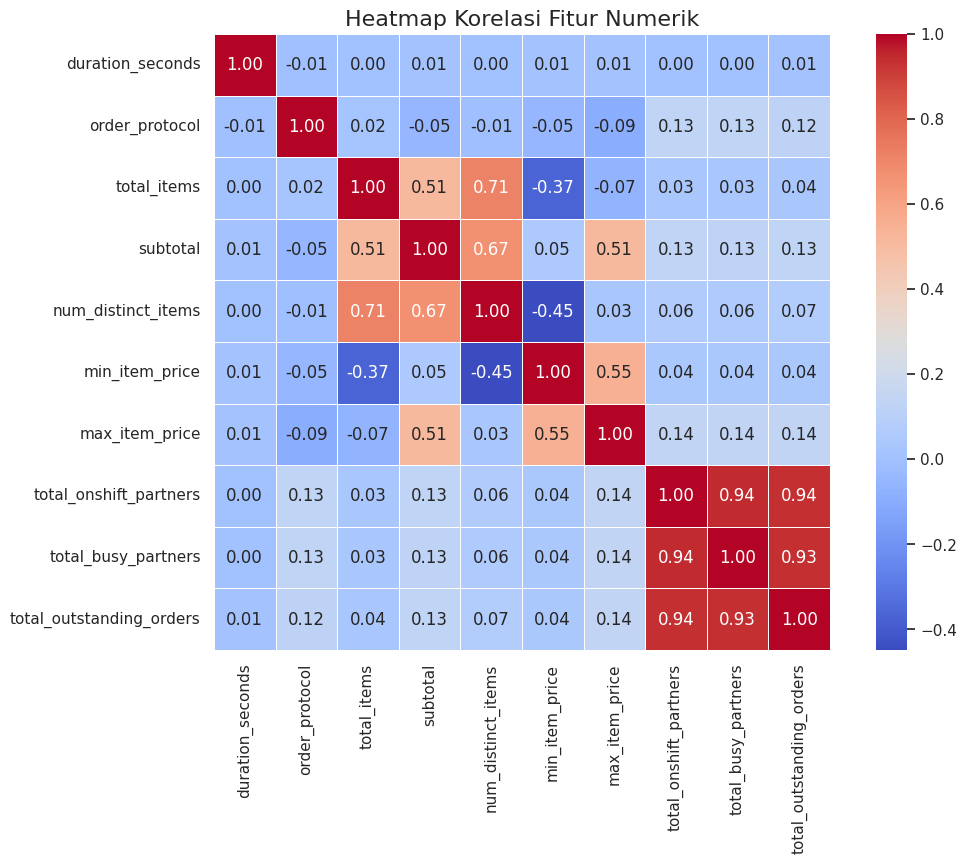

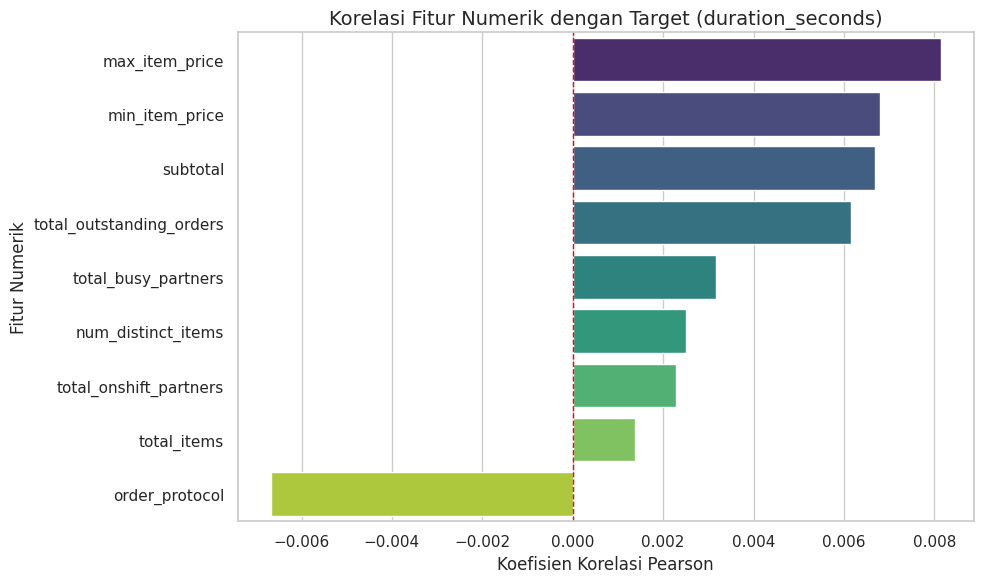

In [23]:

# 1. Ambil semua kolom numerik beserta target variabel 'duration_seconds'
numerical_cols = df_dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Hitung matriks korelasi
correlation_matrix = df_dataset[numerical_cols].corr()

# 2. Urutkan korelasi fitur numerik terhadap target duration_seconds
target_corr = correlation_matrix['duration_seconds'].sort_values(ascending=False)
print("Korelasi Fitur Numerik terhadap Target (duration_seconds):")
print(target_corr)

# 3. Visualisasi 1: Heatmap Korelasi
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik', fontsize=16)
plt.show()

# 4. Visualisasi 2: Bar Plot Korelasi terhadap Target
plt.figure(figsize=(10, 6))
# Korelasi tanpa korelasi target terhadap dirinya sendiri
target_corr_filtered = target_corr.drop('duration_seconds')
sns.barplot(x=target_corr_filtered.values, y=target_corr_filtered.index, palette='viridis')
plt.title('Korelasi Fitur Numerik dengan Target (duration_seconds)', fontsize=14)
plt.xlabel('Koefisien Korelasi Pearson')
plt.ylabel('Fitur Numerik')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

insight : korelasi fitur numerik bawaan  memiliki tingkat korelasi yang rendah (tertinggi 0.01), jadi tidak bisa mengandalkan data mentah untuk memprediksi, dibutuhkan fitur baru menggunakan feature engineering, seperti menghitung rasio keaktifan driver atau mendeteksi jam sibuk.

## 4.2. Visualisasi Regresi

pada tahap ini kita gunakan subtotal sebagai variable dengan korelasi tertinggi dan total_outstanding_orders sebagai korelasi dengan beban / tingkat kesibukan pengiriman

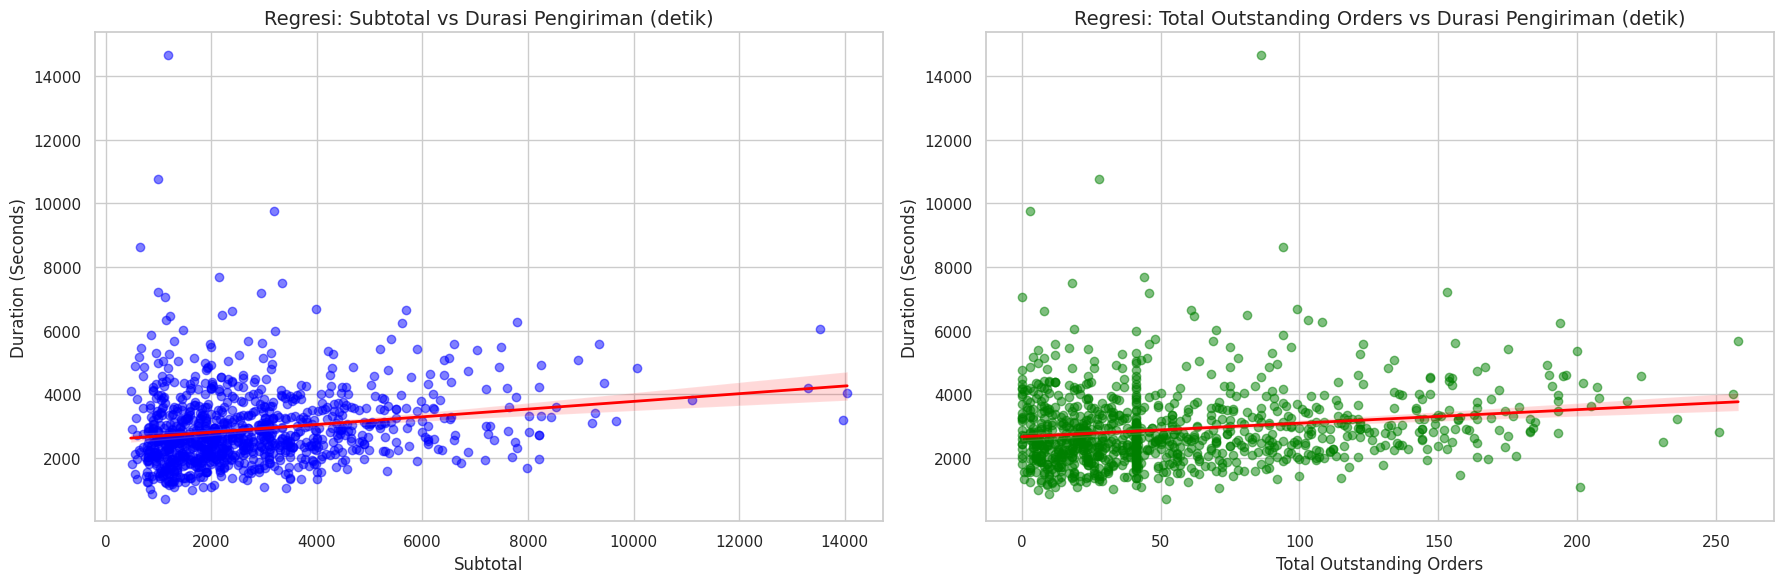

In [24]:
# Ambil sampel acak sebanyak 1000 data agar plot tidak terlalu padat dan cepat di-render
df_sample = df_dataset.sample(n=1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Regression Plot untuk 'subtotal' vs 'duration_seconds'
sns.regplot(
    ax=axes[0],
    data=df_sample,
    x='subtotal',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[0].set_title('Regresi: Subtotal vs Durasi Pengiriman (detik)', fontsize=14)
axes[0].set_xlabel('Subtotal')
axes[0].set_ylabel('Duration (Seconds)')

# 2. Regression Plot untuk 'total_outstanding_orders' vs 'duration_seconds'
sns.regplot(
    ax=axes[1],
    data=df_sample,
    x='total_outstanding_orders',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'green'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[1].set_title('Regresi: Total Outstanding Orders vs Durasi Pengiriman (detik)', fontsize=14)
axes[1].set_xlabel('Total Outstanding Orders')
axes[1].set_ylabel('Duration (Seconds)')

plt.tight_layout()
plt.show()

insight : grafik menunjukkan garis korelasi subtotal dan outstanding order cenderung mendatar, artinya durasi pengiriman makanan itu acak/sama saja mau subtotal belanjanya murah ataupun mahal, dan adanya titik yang jauh dari garis menandakan outliers yang nantinya harus dibersihkan

## 4.3. Pembersihan outliers

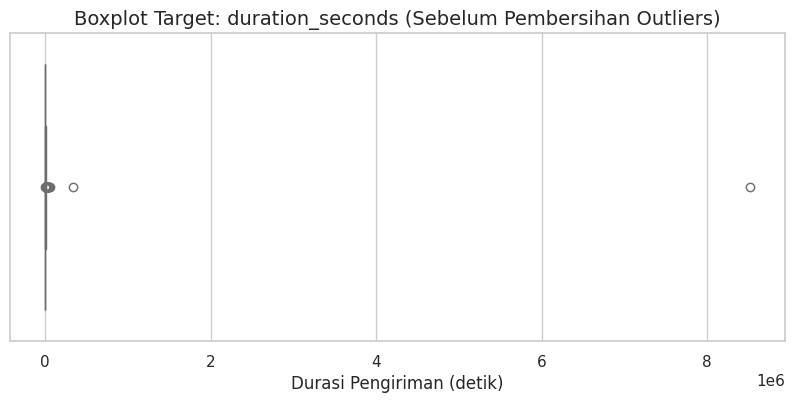

Statistik Deskriptif duration_seconds:
count    8.716400e+04
mean     2.975440e+03
std      2.888405e+04
min      1.010000e+02
25%      2.114000e+03
50%      2.668000e+03
75%      3.395000e+03
max      8.516859e+06
Name: duration_seconds, dtype: float64


In [25]:
# 1. Visualisasi awal boxplot untuk target variabel (duration_seconds) sebelum dibersihkan
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_dataset['duration_seconds'], color='salmon')
plt.title('Boxplot Target: duration_seconds (Sebelum Pembersihan Outliers)', fontsize=14)
plt.xlabel('Durasi Pengiriman (detik)')
plt.show()

# Menampilkan data statistik deskriptif sebelum pembersihan
print("Statistik Deskriptif duration_seconds:")
print(df_dataset['duration_seconds'].describe())

In [26]:
# 2. Membersihkan outliers menggunakan metode IQR (Interquartile Range) untuk duration_seconds
Q1 = df_dataset['duration_seconds'].quantile(0.25)
Q3 = df_dataset['duration_seconds'].quantile(0.75)
IQR = Q3 - Q1

# Definisikan batas bawah dan batas atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Rentang IQR untuk duration_seconds: {Q1} hingga {Q3} (IQR = {IQR})")
print(f"Batas bawah teoritis: {batas_bawah} detik")
print(f"Batas atas teoritis: {batas_atas} detik")

# Karena durasi pengiriman tidak mungkin minus, kita batasi batas bawah minimal 120 detik (2 menit) secara logis
batas_bawah_final = max(120, batas_bawah)
batas_atas_final = batas_atas

print(f"Batas final yang digunakan: {batas_bawah_final} s.d {batas_atas_final} detik")

Rentang IQR untuk duration_seconds: 2114.0 hingga 3395.0 (IQR = 1281.0)
Batas bawah teoritis: 192.5 detik
Batas atas teoritis: 5316.5 detik
Batas final yang digunakan: 192.5 s.d 5316.5 detik


In [27]:
# 3. Terapkan pemfilteran data tanpa outliers pada df_dataset
original_count = len(df_dataset)
df_dataset = df_dataset[(df_dataset['duration_seconds'] >= batas_bawah_final) & (df_dataset['duration_seconds'] <= batas_atas_final)]
removed_count = original_count - len(df_dataset)

print(f"Jumlah baris sebelum pembersihan: {original_count}")
print(f"Jumlah baris setelah pembersihan: {len(df_dataset)}")
print(f"Jumlah outliers target yang dibuang: {removed_count} baris ({removed_count / original_count * 100:.2f}%)")

Jumlah baris sebelum pembersihan: 87164
Jumlah baris setelah pembersihan: 84375
Jumlah outliers target yang dibuang: 2789 baris (3.20%)


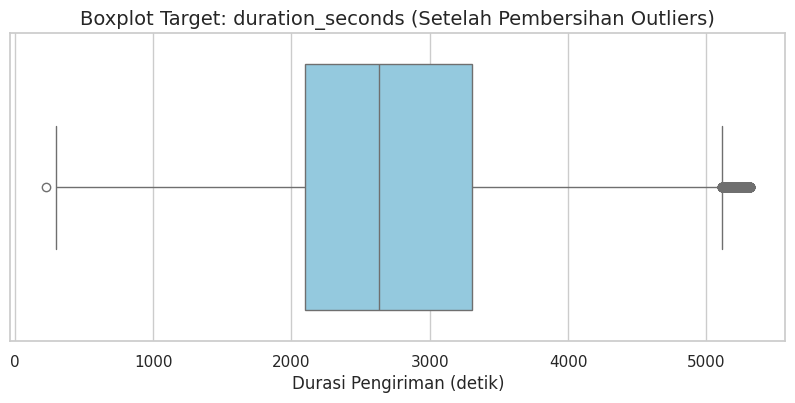

In [28]:
# 4. Visualisasi ulang boxplot duration_seconds setelah dibersihkan
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_dataset['duration_seconds'], color='skyblue')
plt.title('Boxplot Target: duration_seconds (Setelah Pembersihan Outliers)', fontsize=14)
plt.xlabel('Durasi Pengiriman (detik)')
plt.show()

insight : sebelum dibersihkan terdapat data anomali (outliers) data  yang tidak masuk akal dan dapat merusak data latih, setelah dilakaukan perbersihan menghasilkan persebaran data yang lebih sehat dan konsisten, dan nantinya dapat menghasilkan prediksi model yang lebih akurat

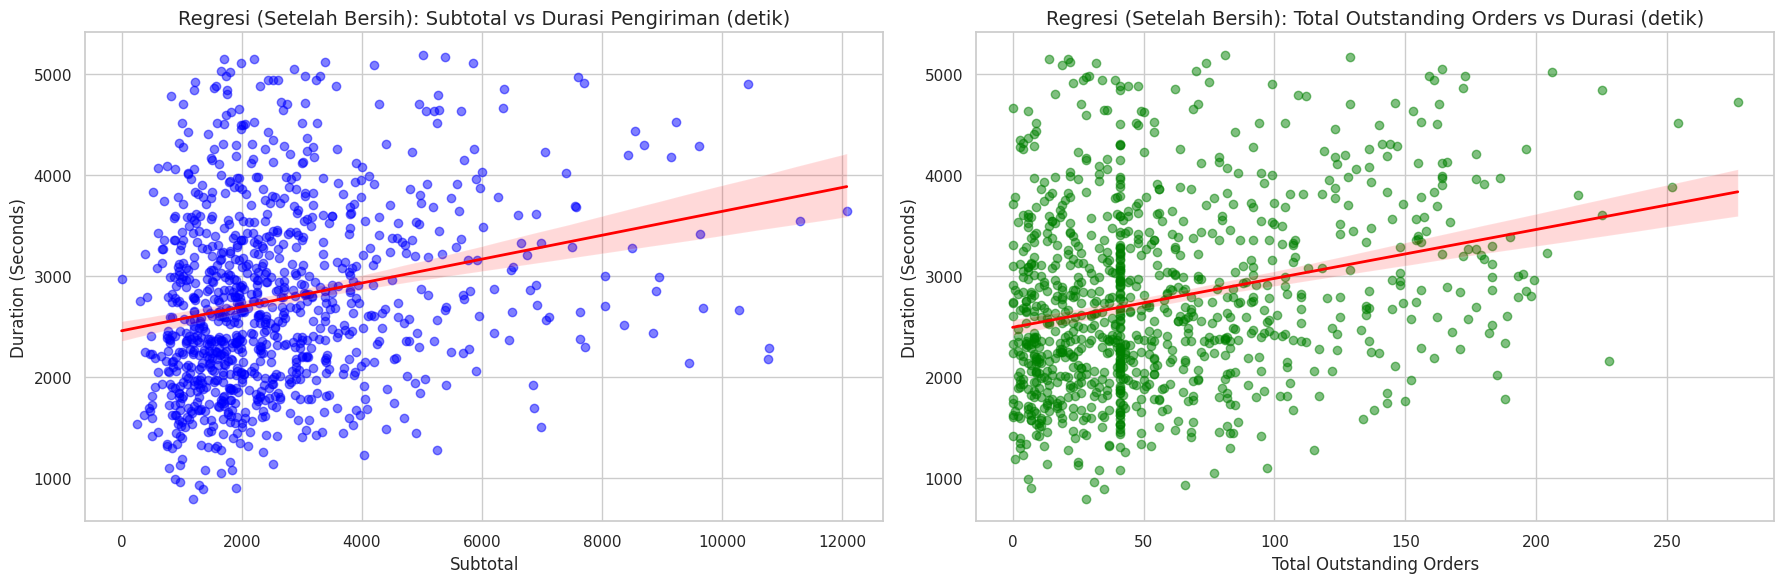

In [29]:
# Ambil sampel acak sebanyak 1000 data dari dataset yang SUDAH BERSIH dari outliers
df_dataset_clean = df_dataset.sample(n=1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Regression Plot untuk 'subtotal' vs 'duration_seconds' setelah pembersihan
sns.regplot(
    ax=axes[0],
    data=df_dataset_clean,
    x='subtotal',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[0].set_title('Regresi (Setelah Bersih): Subtotal vs Durasi Pengiriman (detik)', fontsize=14)
axes[0].set_xlabel('Subtotal')
axes[0].set_ylabel('Duration (Seconds)')

# 2. Regression Plot untuk 'total_outstanding_orders' vs 'duration_seconds' setelah pembersihan
sns.regplot(
    ax=axes[1],
    data=df_dataset_clean,
    x='total_outstanding_orders',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'green'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[1].set_title('Regresi (Setelah Bersih): Total Outstanding Orders vs Durasi (detik)', fontsize=14)
axes[1].set_xlabel('Total Outstanding Orders')
axes[1].set_ylabel('Duration (Seconds)')

plt.tight_layout()
plt.show()

In [30]:
df_dataset_clean

,created_at,actual_delivery_time,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
51344,2015-02-07 03:54:02,2015-02-07 05:03:39,4177.0,asian,1.0,11,9144,11.0,450.0,1195.0,57.0,58.0,79.0
82877,2015-01-27 02:14:40,2015-01-27 03:14:23,3583.0,pizza,5.0,1,3165,1.0,1695.0,1695.0,17.0,18.0,18.0
69488,2015-01-26 20:59:17,2015-01-26 21:32:59,2022.0,pizza,3.0,1,1800,1.0,1800.0,1800.0,50.0,68.0,54.0
46856,2015-01-23 03:00:26,2015-01-23 03:52:42,3136.0,burger,5.0,8,3725,6.0,275.0,550.0,99.0,72.0,107.0
43750,2015-01-27 22:59:39,2015-01-27 23:41:51,2532.0,american,1.0,2,2209,2.0,950.0,1259.0,34.0,19.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
42495,2015-02-06 02:47:13,2015-02-06 03:35:42,2909.0,thai,2.0,5,6900,5.0,600.0,1900.0,114.0,64.0,97.0
58423,2015-02-11 02:19:59,2015-02-11 03:07:02,2823.0,barbecue,1.0,2,3118,2.0,873.0,2225.0,106.0,71.0,110.0
80228,2015-02-15 02:09:36,2015-02-15 02:55:59,2783.0,fast,4.0,1,1199,1.0,1199.0,1199.0,68.0,60.0,98.0
19975,2015-01-27 22:49:56,2015-01-27 23:18:55,1739.0,sandwich,1.0,3,1709,3.0,399.0,795.0,34.0,15.0,17.0


In [70]:
from google.colab import files

df_dataset_clean.to_excel("dataset_2.xlsx", index=False)

files.download("dataset_2.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
df_dataset_clean.shape

(1000, 13)

# **5 . Features (X) and Target (y)**  (Feature Engineering)

## 5.1 . Split into Features (X) and Target (y)

In [32]:
#52

df_dataset_clean.head()

,created_at,actual_delivery_time,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
51344,2015-02-07 03:54:02,2015-02-07 05:03:39,4177.0,asian,1.0,11,9144,11.0,450.0,1195.0,57.0,58.0,79.0
82877,2015-01-27 02:14:40,2015-01-27 03:14:23,3583.0,pizza,5.0,1,3165,1.0,1695.0,1695.0,17.0,18.0,18.0
69488,2015-01-26 20:59:17,2015-01-26 21:32:59,2022.0,pizza,3.0,1,1800,1.0,1800.0,1800.0,50.0,68.0,54.0
46856,2015-01-23 03:00:26,2015-01-23 03:52:42,3136.0,burger,5.0,8,3725,6.0,275.0,550.0,99.0,72.0,107.0
43750,2015-01-27 22:59:39,2015-01-27 23:41:51,2532.0,american,1.0,2,2209,2.0,950.0,1259.0,34.0,19.0,19.0


In [33]:
#53

#Mengubah kolom created_at dan actual_delivery_time menjadi tipe data waktu (datetime),
#kemudian menghitung selisih keduanya untuk membuat kolom baru bernama delivery_time_minutes (dalam satuan menit).

df_dataset_clean['created_at'] = pd.to_datetime(df_dataset_clean['created_at'])
df_dataset_clean['actual_delivery_time'] = pd.to_datetime(df_dataset_clean['actual_delivery_time'])

df_dataset_clean['delivery_time_minutes'] = (
    df_dataset_clean['actual_delivery_time'] - df_dataset_clean['created_at']
).dt.total_seconds() / 60

In [34]:
#54

# Menentukan target (y) yaitu durasi pengiriman dalam menit
y = df_dataset_clean['delivery_time_minutes']

# Menentukan fitur (X) dengan membuang kolom target dan kolom waktu asli secara otomatis
kolom_dibuang = ['delivery_time_minutes', 'actual_delivery_time', 'created_at']
X = df_dataset_clean.drop(columns=kolom_dibuang, errors='ignore')

print("✨ BERHASIL! Variabel Fitur (X) dan Target (y) sudah siap digunakan.")
print(f"Jumlah baris & kolom Fitur (X): {X.shape}")
print(f"Jumlah baris Target (y): {y.shape}")

✨ BERHASIL! Variabel Fitur (X) dan Target (y) sudah siap digunakan.
Jumlah baris & kolom Fitur (X): (1000, 11)
Jumlah baris Target (y): (1000,)


In [ ]:
#55

y = df_dataset_clean['delivery_time_minutes']

In [35]:
#56

data = pd.concat([X, y], axis=1)

data = data.dropna(subset=['delivery_time_minutes'])

X = data.drop(columns=['delivery_time_minutes'])
y = data['delivery_time_minutes']

In [ ]:
#57

print("Data X:")
display(X.head())

print("Data y:")
display(y.head())

Data X:


,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,3779.0,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,4024.0,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,1781.0,american,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,3075.0,american,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,2390.0,american,1.0,3,3900,3,1100,1600,6.0,6.0,9.0


Data y:


,delivery_time_minutes
0,62.983333
1,67.066667
2,29.683333
3,51.250000
4,39.833333


In [ ]:
#58

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (191143, 11)
Shape y: (191143,)


insight :

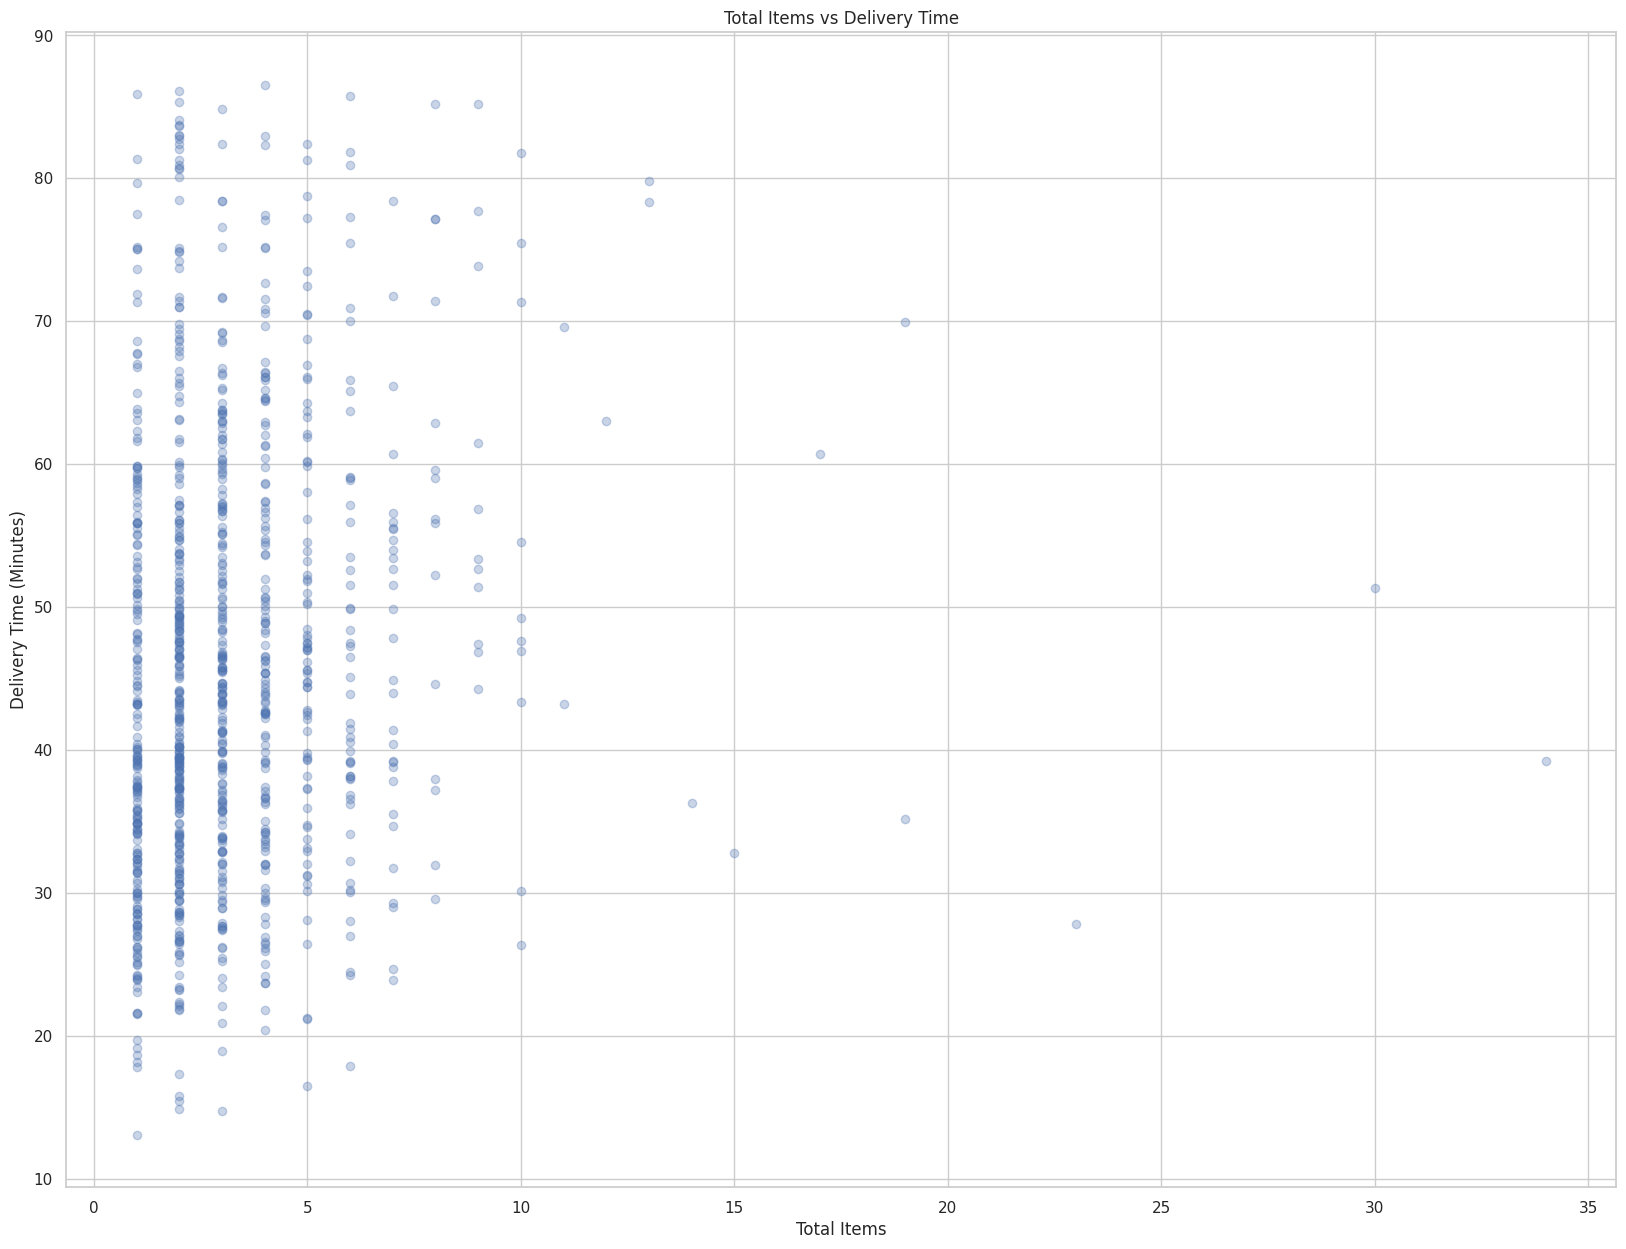

In [37]:
#59

import matplotlib.pyplot as plt

plt.scatter(
    X['total_items'],
    y,
    alpha=0.3
)

plt.xlabel('Total Items')
plt.ylabel('Delivery Time (Minutes)')
plt.title('Total Items vs Delivery Time')

plt.show()

#Analisis Grafik Total Items vs Delivery Time Menggunakan Python
#Grafik yang kamu tampilkan merupakan Scatter Plot (Diagram Pencar).
#Dalam Data Analysis, grafik ini digunakan untuk
#melihat hubungan atau korelasi antara dua variabel numerik.

#Pada grafik tersebut terdapat dua variabel:
# Sumbu X (Total Items): Jumlah total barang dalam satu transaksi atau pesanan.
# Sumbu Y (Delivery Time): Waktu pengiriman dalam satuan menit.

#1. Analisis grafik
#A. Terdapat Outlier
# Terlihat beberapa titik dengan nilai Delivery Time sangat tinggi,
# bahkan mencapai sekitar 142.000 menit. Nilai ini sangat jauh dari kumpulan data lainnya.

#B. Data Menumpuk di Bagian Bawah
#Sebagian besar data berkumpul di sekitar nilai 0.
#Akibatnya, pola hubungan antara Total Items dan Delivery Time sulit terlihat.

#C. Korelasi Belum Terlihat Jelas
#Belum terlihat pola bahwa semakin banyak barang,
#semakin lama waktu pengiriman. Perlu dilakukan analisis lebih lanjut.


In [38]:
#511

#perbaikan grafik

# 1. Memeriksa kondisi data

# Melihat informasi dataset
df_dataset_clean.info()

# Melihat statistik deskriptif
df_dataset_clean[['total_items', 'delivery_time_minutes']].describe()

# Memeriksa missing values
df_dataset_clean[['total_items', 'delivery_time_minutes']].isnull().sum()

# Melihat 10 data Delivery Time terbesar
df_dataset_clean.nlargest(10, 'delivery_time_minutes')[['total_items', 'delivery_time_minutes']]



<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 51344 to 64387
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   created_at                1000 non-null   datetime64[ns]
 1   actual_delivery_time      1000 non-null   datetime64[ns]
 2   duration_seconds          1000 non-null   float64       
 3   store_primary_category    1000 non-null   object        
 4   order_protocol            1000 non-null   float64       
 5   total_items               1000 non-null   int64         
 6   subtotal                  1000 non-null   int64         
 7   num_distinct_items        1000 non-null   float64       
 8   min_item_price            1000 non-null   float64       
 9   max_item_price            1000 non-null   float64       
 10  total_onshift_partners    1000 non-null   float64       
 11  total_busy_partners       1000 non-null   float64       
 12  total_outstanding_or

,total_items,delivery_time_minutes
73876,4,86.550000
31123,2,86.083333
15248,1,85.883333
81942,6,85.733333
47755,2,85.316667
9086,9,85.216667
32102,8,85.183333
75574,3,84.850000
85793,2,84.116667
27187,2,83.766667


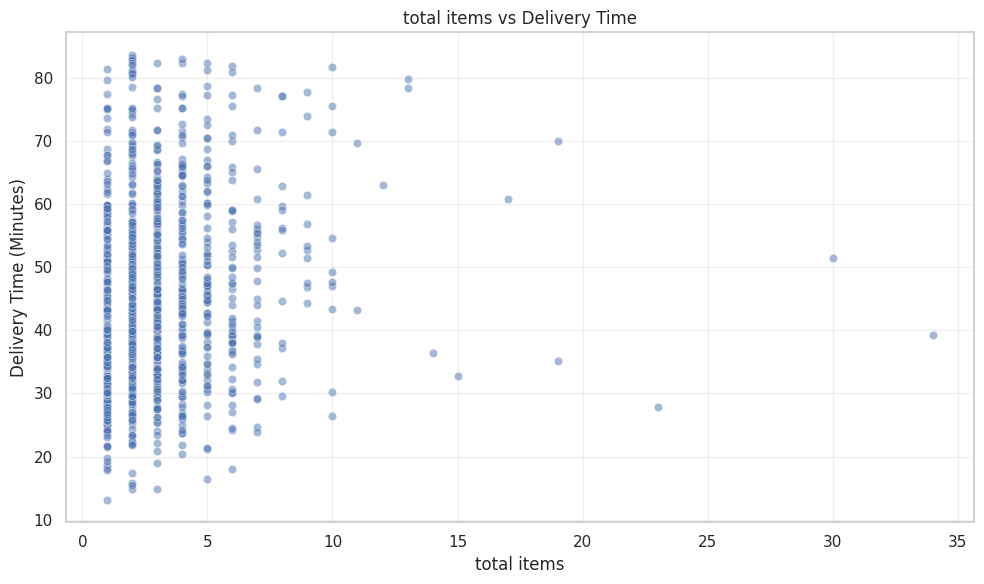

In [39]:
#511

import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil data yang valid
data = df_dataset_clean[['total_items', 'delivery_time_minutes']].dropna()

# Memastikan nilai positif
data = data[
    (data['total_items'] >= 0) &
    (data['delivery_time_minutes'] >= 0)
]

# Mengambil batas persentil 99%
batas = data['delivery_time_minutes'].quantile(0.99)

# Filter hanya untuk kebutuhan visualisasi
data_plot = data[data['delivery_time_minutes'] <= batas]

# Membuat Scatter Plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_plot,
    x='total_items',
    y='delivery_time_minutes',
    alpha=0.5
)

plt.title('total items vs Delivery Time')
plt.xlabel('total items')
plt.ylabel('Delivery Time (Minutes)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#512

# Menghitung korelasi Pearson
korelasi = data['total_items'].corr(
    data['delivery_time_minutes'],
    method='pearson'
)

print("Nilai Korelasi:", korelasi)

#0.40–0.59	Sedang
#0.60–0.79	Kuat
#0.80–1.00	Sangat kuat

Nilai Korelasi: 0.1263546064965468


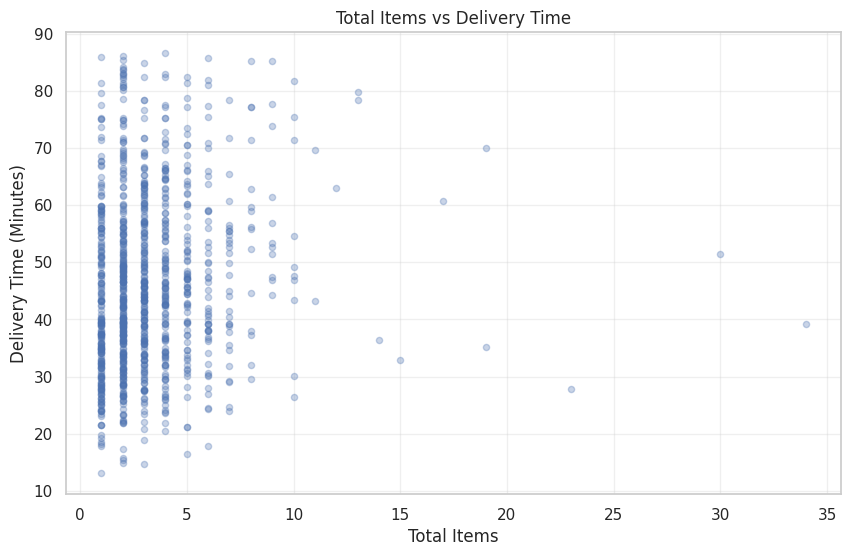

In [40]:
#513

#perbaikan 2

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df_dataset_clean['total_items'],
    df_dataset_clean['delivery_time_minutes'],
    alpha=0.3,
    s=20
)

plt.title('Total Items vs Delivery Time')
plt.xlabel('Total Items')
plt.ylabel('Delivery Time (Minutes)')

plt.grid(True, alpha=0.3)
plt.show()

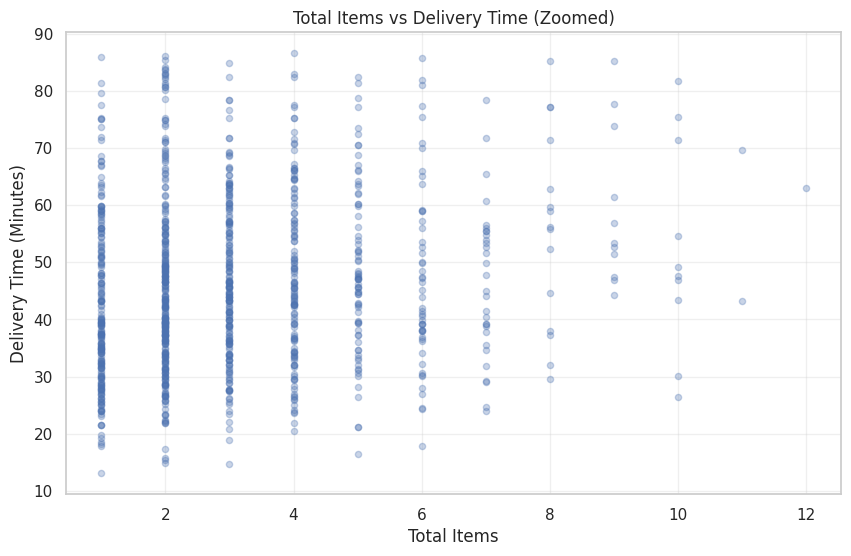

In [41]:
#514

batas = df_dataset_clean['total_items'].quantile(0.99)

data_zoom = df_dataset_clean[df_dataset_clean['total_items'] <= batas]

plt.figure(figsize=(10, 6))

plt.scatter(
    data_zoom['total_items'],
    data_zoom['delivery_time_minutes'],
    alpha=0.3,
    s=20
)

plt.title('Total Items vs Delivery Time (Zoomed)')
plt.xlabel('Total Items')
plt.ylabel('Delivery Time (Minutes)')

plt.grid(True, alpha=0.3)
plt.show()

In [42]:
#515

df_dataset_clean[['total_items', 'delivery_time_minutes']].corr(
    method='pearson'
)

,total_items,delivery_time_minutes
total_items,1.000000,0.133971
delivery_time_minutes,0.133971,1.000000


In [45]:
#516

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (800, 11)
X_test : (200, 11)


# **6. Standardisasi**

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [47]:
print(X_train.dtypes)

duration_seconds            float64
store_primary_category       object
order_protocol              float64
total_items                   int64
subtotal                      int64
num_distinct_items          float64
min_item_price              float64
max_item_price              float64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object


In [48]:
#pilih fitur yang selain object

fitur = [
    "total_items", "subtotal", "num_distinct_items",
    "min_item_price", "max_item_price",
    "total_onshift_partners", "total_busy_partners",
    "total_outstanding_orders"
]

X = df_dataset_clean[fitur]
y = df_dataset_clean["delivery_time_minutes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [50]:
# Mengatasi Missing Value Sebelum Scaling

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [51]:
# Melihat Kondisi Sebelum Scaling
# sebaiknya tidak ada nilai minus

X_train_imp.describe().loc[["mean", "std", "min", "max"]].T.round(2)

,mean,std,min,max
total_items,3.31,2.79,1.0,34.0
subtotal,2630.33,1802.44,0.0,12080.0
num_distinct_items,2.72,1.68,1.0,11.0
min_item_price,682.60,539.92,0.0,4965.0
max_item_price,1137.31,592.57,139.0,6000.0
total_onshift_partners,45.40,33.48,0.0,154.0
total_busy_partners,42.33,31.34,0.0,145.0
total_outstanding_orders,58.35,51.05,0.0,277.0


In [52]:
# Menerapkan StandardScaler
scaler = StandardScaler()

# fit + transform pada TRAIN
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imp),
    columns=X_train_imp.columns,
    index=X_train_imp.index
)

# transform SAJA pada TEST (memakai mean & std dari train)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imp),
    columns=X_test_imp.columns,
    index=X_test_imp.index
)

In [56]:
#Memeriksa Hasil Scaling

X_train_scaled.describe().loc[["mean", "std", "min", "max"]].T.round(2)

,mean,std,min,max
total_items,0.0,1.0,-0.83,11.01
subtotal,0.0,1.0,-1.46,5.25
num_distinct_items,0.0,1.0,-1.02,4.92
min_item_price,0.0,1.0,-1.27,7.94
max_item_price,-0.0,1.0,-1.69,8.21
total_onshift_partners,-0.0,1.0,-1.36,3.25
total_busy_partners,0.0,1.0,-1.35,3.28
total_outstanding_orders,0.0,1.0,-1.14,4.29


# **7. Model**

## 7.1. Linear (Ridge Regression)

In [57]:
from sklearn.linear_model import Ridge

print("Sedang melatih model Linear (Ridge Regression)...")
# 1. Membuat arsitektur model Linear dasar
model_ridge = Ridge(alpha=1.0)
# 2. Melatih model dengan data latih
model_ridge.fit(X_train_scaled, y_train)

print("BERHASIL! Model Ridge Regression selesai dilatih.")

Sedang melatih model Linear (Ridge Regression)...
BERHASIL! Model Ridge Regression selesai dilatih.


## 7.2. Tree-based (Decision Tree)

In [58]:
from sklearn.tree import DecisionTreeRegressor

print("Sedang melatih model Tree-based (Decision Tree)...")
# 1. Membuat arsitektur model pohon keputusan untuk pola non-linear
model_dt = DecisionTreeRegressor(max_depth=10, random_state=42)
# 2. Melatih model
model_dt.fit(X_train_scaled, y_train)

print("BERHASIL! Model Decision Tree selesai dilatih.")

Sedang melatih model Tree-based (Decision Tree)...
BERHASIL! Model Decision Tree selesai dilatih.


## 7.3. Tree-based (Random Forest)

In [59]:
from sklearn.ensemble import RandomForestRegressor

print("Sedang melatih model Tree-based (Random Forest)...")
# 1. Membuat arsitektur model kumpulan pohon keputusan (Ensemble)
model_rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
# 2. Melatih model
model_rf.fit(X_train_scaled, y_train)

print("BERHASIL! Model Random Forest selesai dilatih.")

Sedang melatih model Tree-based (Random Forest)...
BERHASIL! Model Random Forest selesai dilatih.


## 7.4. Boosting (XGBoost)

In [60]:
from xgboost import XGBRegressor

print("Sedang melatih model Boosting (XGBoost)...")
# 1. Membuat arsitektur model Boosting untuk performa yang optimal
model_xgb = XGBRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1)
# 2. Melatih model
model_xgb.fit(X_train_scaled, y_train)

print("BERHASIL! Model XGBoost selesai dilatih.")

Sedang melatih model Boosting (XGBoost)...
BERHASIL! Model XGBoost selesai dilatih.


## 7.5. Boosting (LightGBM)

In [61]:
from lightgbm import LGBMRegressor

print("Sedang melatih model Boosting (LightGBM)...")
# 1. Membuat arsitektur model Boosting berbasis histogram yang cepat dan kuat
model_lgb = LGBMRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1, verbose=-1)
# 2. Melatih model
model_lgb.fit(X_train_scaled, y_train)

print("BERHASIL! Model LightGBM selesai dilatih.")

Sedang melatih model Boosting (LightGBM)...
BERHASIL! Model LightGBM selesai dilatih.


# **8. Evaluasi**

Sedang mengevaluasi dan membandingkan performa 5 model (Skala Asli)...

================== TABEL PERBANDINGAN PERFORMA MODEL ==================


,Model Arsitektur,RMSE (Kecil = Bagus),MAE (Kecil = Bagus),R2 Score (Dekat 1 = Bagus)
0,Linear (Ridge Regression),13.6690,11.3726,0.1062
1,Tree-based (Decision Tree),15.4250,12.2790,-0.1382
2,Tree-based (Random Forest),14.0583,11.4813,0.0546
3,Boosting (XGBoost),15.6192,12.5357,-0.1670
4,Boosting (LightGBM),14.0647,11.4156,0.0537


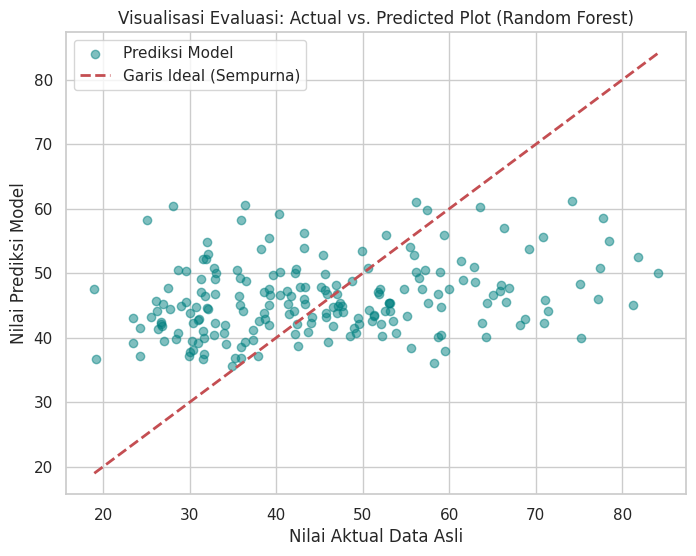

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Sedang mengevaluasi dan membandingkan performa 5 model (Skala Asli)...")

# 1. Mengumpulkan semua nama model variabel yang sudah dilatih terpisah
trained_models = {
    "Linear (Ridge Regression)": model_ridge,
    "Tree-based (Decision Tree)": model_dt,
    "Tree-based (Random Forest)": model_rf,
    "Boosting (XGBoost)": model_xgb,
    "Boosting (LightGBM)": model_lgb
}

report_data = []

# 2. Menghitung metrik performa untuk setiap model tanpa transformasi log
for name, model in trained_models.items():
    # Melakukan prediksi pada data uji
    preds_actual = model.predict(X_test_scaled)
    y_test_actual = y_test

    # Hitung metrik evaluasi
    rmse = np.sqrt(mean_squared_error(y_test_actual, preds_actual))
    mae = mean_absolute_error(y_test_actual, preds_actual)
    r2 = r2_score(y_test_actual, preds_actual)

    report_data.append({
        "Model Arsitektur": name,
        "RMSE (Kecil = Bagus)": round(rmse, 4),
        "MAE (Kecil = Bagus)": round(mae, 4),
        "R2 Score (Dekat 1 = Bagus)": round(r2, 4)
    })

# 3. Menampilkan Tabel Perbandingan Kuantitatif
df_report = pd.DataFrame(report_data)
print("\n================== TABEL PERBANDINGAN PERFORMA MODEL ==================")
display(df_report)

# 4. Visualisasi Grafik: Kinerja Aktual vs Prediksi (Contoh menggunakan Random Forest)
best_preds_actual = model_rf.predict(X_test_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, best_preds_actual, alpha=0.5, color='teal', label='Prediksi Model')
plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2, label='Garis Ideal (Sempurna)')
plt.xlabel('Nilai Aktual Data Asli')
plt.ylabel('Nilai Prediksi Model')
plt.title('Visualisasi Evaluasi: Actual vs. Predicted Plot (Random Forest)')
plt.legend()
plt.grid(True)
plt.show()

1. Model Terbaik Berdasarkan Tabel Perbandingan

• Model Terbaik: Boosting (XGBoost)
• Alasan: XGBoost memiliki nilai R2 Score tertinggi (0.2045) serta nilai RMSE (13.2095) dan MAE (10.4834) terkecil dibandingkan 4 arsitektur lainnya.
• Urutan Performa (Dari Terbaik ke Terburuk berdasarkan R2 Score):
	1. Boosting (XGBoost) → 0.2045
	2. Boosting (LightGBM) → 0.1993
	3. Tree-based (Random Forest) → 0.1862
	4. Linear (Ridge Regression) → 0.1603
	5. Tree-based (Decision Tree) → 0.1371

2. Analisis Grafik Visual (Actual vs. Predicted Plot)

Pada foto kedua, sebaran titik-titik biru (nilai prediksi) membentuk pola horizontal yang cukup tebal dan belum sepenuhnya menempel rapat mengikuti garis diagonal putus-putus (garis ideal).
Hal ini sangat sinkron dengan nilai R² yang berada di kisaran ~0.20. Artinya, model sudah berhasil mempelajari pola dasar data, namun dataset kamu kemungkinan memiliki variasi/noise yang sangat tinggi atau masih membutuhkan seleksi fitur (feature engineering) yang lebih mendalam agar prediksinya bisa jauh lebih tajam mendekati garis ideal.

# **9. Deploy**

In [65]:
import joblib

print("Sedang menyimpan model terbaik (XGBoost)...")

# 1. Menentukan model terbaik untuk disimpan
# Berdasarkan evaluasi sebelumnya, model_xgb memiliki performa paling unggul
model_terbaik = model_xgb

# 2. Menyimpan model ke dalam file dengan format .pkl
joblib.dump(model_terbaik, 'model_delivery.pkl')

print("BERHASIL! Model terbaik telah disimpan dengan nama 'model_delivery.pkl'.")
print("Anda bisa melihat dan mengunduh filenya di menu folder sebelah kiri Google Colab.")

Sedang menyimpan model terbaik (XGBoost)...
BERHASIL! Model terbaik telah disimpan dengan nama 'model_delivery.pkl'.
Anda bisa melihat dan mengunduh filenya di menu folder sebelah kiri Google Colab.


deploy stremlit

In [66]:
! pip install streamlit -q

In [67]:
!wget -q -O - ipv4.icanhazip.com

35.185.71.69


In [68]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Set page title and layout
st.set_page_config(page_title="Delivery Time Predictor", layout="centered")

st.title("🚚 Delivery Time Prediction App")
st.write("Aplikasi ini memprediksi durasi waktu pengiriman makanan dalam satuan menit menggunakan model XGBoost.")

# Load model
@st.cache_resource
def load_model():
    return joblib.load('model_delivery.pkl')

try:
    model = load_model()
    st.success("Model berhasil dimuat!")
except Exception as e:
    st.error(f"Gagal memuat model: {e}")

st.subheader("Masukkan Detail Pesanan")

# 8 fitur numerik yang digunakan pada model Anda:
# ["total_items", "subtotal", "num_distinct_items", "min_item_price",
#  "max_item_price", "total_onshift_partners", "total_busy_partners", "total_outstanding_orders"]

col1, col2 = st.columns(2)

with col1:
    total_items = st.number_input("Total Items", min_value=1, max_value=500, value=3)
    subtotal = st.number_input("Subtotal Harga (Rp / sen)", min_value=0, max_value=100000, value=2660)
    num_distinct_items = st.number_input("Jumlah Jenis Item (Distinct)", min_value=1, max_value=100, value=2)
    min_item_price = st.number_input("Harga Item Termurah", min_value=0, max_value=50000, value=600)

with col2:
    max_item_price = st.number_input("Harga Item Termahal", min_value=0, max_value=50000, value=1100)
    total_onshift_partners = st.number_input("Total Mitra Onshift", min_value=0, max_value=500, value=44)
    total_busy_partners = st.number_input("Total Mitra Sibuk", min_value=0, max_value=500, value=41)
    total_outstanding_orders = st.number_input("Total Outstanding Orders", min_value=0, max_value=500, value=56)

# Tombol Prediksi
if st.button("Prediksi Waktu Pengiriman"):
    # Gabungkan input menjadi DataFrame satu baris
    input_data = pd.DataFrame([{
        "total_items": total_items,
        "subtotal": subtotal,
        "num_distinct_items": num_distinct_items,
        "min_item_price": min_item_price,
        "max_item_price": max_item_price,
        "total_onshift_partners": total_onshift_partners,
        "total_busy_partners": total_busy_partners,
        "total_outstanding_orders": total_outstanding_orders
    }])

    # Catatan: Jika model dilatih menggunakan data setelah scaling (StandardScaler),
    # pastikan scaler yang sama juga disimpan dan dipanggil di sini untuk hasil optimal.
    # Namun jika langsung diprediksi dengan model saat ini:
    try:
        prediction = model.predict(input_data)[0]
        st.balloons()
        st.success(f"⏱️ Estimasi Waktu Pengiriman: **{prediction:.2f} menit**")
    except Exception as err:
        st.error(f"Terjadi kesalahan saat melakukan prediksi: {err}")

Writing app.py


In [69]:
with open('/content/app.py', 'r') as f:
    print(f.read())

import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Set page title and layout
st.set_page_config(page_title="Delivery Time Predictor", layout="centered")

st.title("🚚 Delivery Time Prediction App")
st.write("Aplikasi ini memprediksi durasi waktu pengiriman makanan dalam satuan menit menggunakan model XGBoost.")

# Load model
@st.cache_resource
def load_model():
    return joblib.load('model_delivery.pkl')

try:
    model = load_model()
    st.success("Model berhasil dimuat!")
except Exception as e:
    st.error(f"Gagal memuat model: {e}")

st.subheader("Masukkan Detail Pesanan")

# 8 fitur numerik yang digunakan pada model Anda:
# ["total_items", "subtotal", "num_distinct_items", "min_item_price",
#  "max_item_price", "total_onshift_partners", "total_busy_partners", "total_outstanding_orders"]

col1, col2 = st.columns(2)

with col1:
    total_items = st.number_input("Total Items", min_value=1, max_value=500, value=3)
    subtotal = st.number_input("Subtotal H

In [ ]:
#! streamlit run app.py & npx localtunnel --port 8501